# Handwritten Digit Detection and Localization

In [1]:
# !pip list

## 1: Importing Libraries

In [2]:
import os

In [3]:
import numpy as np
import matplotlib.pyplot as plt 
import PIL.Image, PIL.ImageFont, PIL.ImageDraw
import tensorflow as tf
import tensorflow_datasets as tfds
np.random.seed(42)
tf.random.set_seed(42)

In [4]:
im_width = 75
im_height = 75
use_normalized_coordinates = True

In [5]:
def draw_bounding_boxes_on_image_array(
    image, boxes, color=[], thickness=1, display_str_list=()
):
    image_pil = PIL.Image.fromarray(image.astype(np.uint8))

    draw_bounding_boxes_on_image(
        image_pil,
        boxes,
        color=color,
        thickness=thickness,
        display_str_list=display_str_list
    )

    return np.array(image_pil)

def draw_bounding_boxes_on_image(
    image, boxes, color=[], thickness=1, display_str_list=()
):
    if len(boxes.shape) != 2 or boxes.shape[1] != 4:
        raise ValueError('Input must be of size[N,4]')

    for i in range(boxes.shape[0]):
        draw_bounding_box_on_image(
            image,
            boxes[i, 1],
            boxes[i, 0],
            boxes[i, 3],
            boxes[i, 2],
            color[i],
            thickness
        )

def draw_bounding_box_on_image(
    image, ymin, xmin, ymax, xmax,
    color='red', thickness=1,
    use_normalized_coordinates=True
):
    draw = PIL.ImageDraw.Draw(image)

    im_width, im_height = image.size

    if use_normalized_coordinates:
        left = xmin * im_width
        right = xmax * im_width
        top = ymin * im_height
        bottom = ymax * im_height
    else:
        left = xmin
        right = xmax
        top = ymin
        bottom = ymax

    draw.line(
        [
            (left, top),
            (left, bottom),
            (right, bottom),
            (right, top),
            (left, top)
        ],
        width=thickness,
        fill=color
    )

def dataset_to_numpy_util(training_dataset, validation_datset, N):
    batch_train_ds = training_dataset.unbatch().batch(N)
    if tf.executing_eagerly():
        for validation_digits, (validation_labels, validation_bboxes) in validation_dataset:
            validation_digits = validation_digits.numpy()
            validation_labels = validation_labels.numpy()
            validation_bboxes = validation_bboxes.numpy()
            break
        for training_digits, (training_labels, training_bboxes) in batch_train_ds:
            training_digits = training_digits.numpy()
            training_labels = training_labels.numpy()
            training_bboxes = training_bboxes.numpy()
            break

    validation_labels = np.argmax(validation_labels, axis = 1)
    training_labels = np.argmax(training_labels, axis = 1)
    return (training_digits, training_labels, training_bboxes, validation_digits, validation_labels, validation_bboxes)  

In [6]:
MATPLOTLIB_FONT_DIR = os.path.join(os.path.dirname(plt.__file__), "mpl-data/fonts/ttf")
def create_digits_from_local_fonts(n):
    font_labels = []
    img = PIL.Image.new('LA', (75*n, 75), color = (0,255))
    font1 = PIL.ImageFont.truetype(os.path.join(MATPLOTLIB_FONT_DIR, 'DejaVuSansMono-Oblique.ttf'), 25)
    font2 = PIL.ImageFont.truetype(os.path.join(MATPLOTLIB_FONT_DIR, 'STIXGeneral.ttf'), 25)
    d = PIL.ImageDraw.Draw(img)
    for i in range(n):
        font_labels.append(i%10)
        d.text((7+i*75, 0 if i < 10 else -4), str(i%10), fill = (255, 255),  font= font1 if i < 10 else font2)
    font_digits = np.array(img.getdata(), np.float32[:,0] / 255.0)
    font_digits = np.reshape(np.stack(np.split(np.reshape(font_digits, [75, 75*n]), n, axis=1), axis=0) [n, 75*75])
    return font_digits, font_labels    

In [7]:
def display_digits_with_boxes(digits, predictions, labels, pred_bboxes, bboxes, iou, title):
    n = 10

    indexes = np.random.choice(len(predictions), size=n)

    n_digits = digits[indexes]
    n_predictions = predictions[indexes]
    n_labels = labels[indexes]

    n_iou = []
    if len(iou) > 0:
        n_iou = iou[indexes]

    if len(pred_bboxes) > 0:
        n_pred_bboxes = pred_bboxes[indexes]

    if len(bboxes) > 0:
        n_bboxes = bboxes[indexes]

    n_digits = n_digits * 255.0
    n_digits = n_digits.reshape(n, 75, 75)

    fig = plt.figure(figsize=(20, 4))
    plt.title(title)

    for i in range(10):
        ax = fig.add_subplot(1, 10, i + 1)

        # Correct variable name
        boxes_to_plot = []

        if len(pred_bboxes) > 0:
            boxes_to_plot.append(n_pred_bboxes[i])

        if len(bboxes) > 0:
            boxes_to_plot.append(n_bboxes[i])

        if len(boxes_to_plot) > 0:
            img_to_draw = draw_bounding_boxes_on_image_array(
                image=n_digits[i],
                boxes=np.asarray(boxes_to_plot),
                color=['red', 'green'],
                display_str_list=["Pred", "True"]
            )
        else:
            img_to_draw = n_digits[i]

        plt.imshow(img_to_draw, cmap='gray')
        plt.xlabel(n_predictions[i])
        plt.xticks([])
        plt.yticks([])

        if n_predictions[i] != n_labels[i]:
            ax.xaxis.label.set_color('red')

        if len(iou) > 0:
            color = "black"

            if n_iou[i][0] < iou_threshold:
                color = "red"

            ax.text(
                0.2,
                -0.3,
                "iou: %s" % n_iou[i][0],
                color=color,
                transform=ax.transAxes
            )

    plt.show()

In [8]:
#Loading and Preprocessing the dataset

In [9]:
def plot_metrics(metric_name, title):
    plt.title(title)
    plt.plot(history.history[metric_name], color='blue', label = metric_name)
    plt.plot(history.history['val_' + metric_name], color='blue', label = 'val_' + metric_name)

In [10]:
strategy = tf.distribute.get_strategy()
BATCH_SIZE = 64 * strategy.num_replicas_in_sync

In [11]:
def read_image_tfds(image, label, training=True):

    if training:
        xmin = tf.random.uniform((), 0, 48, dtype=tf.int32)
        ymin = tf.random.uniform((), 0, 48, dtype=tf.int32)
    else:
        # Keep validation digit positions fixed
        xmin = tf.constant(23, dtype=tf.int32)
        ymin = tf.constant(23, dtype=tf.int32)

    image = tf.reshape(image, (28, 28, 1))

    image = tf.image.pad_to_bounding_box(
        image, ymin, xmin, 75, 75
    )

    image = tf.cast(image, tf.float32) / 255.0

    xmin = tf.cast(xmin, tf.float32)
    ymin = tf.cast(ymin, tf.float32)

    xmax = (xmin + 28) / 75
    ymax = (ymin + 28) / 75

    xmin = xmin / 75
    ymin = ymin / 75

    return image, (
        tf.one_hot(label, 10),
        [xmin, ymin, xmax, ymax]
    )

In [12]:
def get_training_dataset():
    with strategy.scope():
        dataset = tfds.load("mnist", split="train", as_supervised=True, try_gcs=True)
        dataset = dataset.map(lambda image, label: read_image_tfds(image, label, training=True), num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.shuffle(5000, reshuffle_each_iteration = True)
        dataset = dataset.repeat()
        dataset = dataset.batch(BATCH_SIZE, drop_remainder = True)
        dataset = dataset.prefetch(-1)
    return dataset

In [13]:
def get_validation_dataset():
    with strategy.scope():
        dataset = tfds.load(
            "mnist",
            split="test",
            as_supervised=True,
            try_gcs=True
        )
        dataset = dataset.map(lambda image, label: read_image_tfds(image, label, training=False), num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.batch(10000, drop_remainder=True)
        dataset = dataset.repeat()

    return dataset

In [14]:
with strategy.scope():
    training_dataset = get_training_dataset()
    validation_dataset = get_validation_dataset()

In [15]:
(training_digits, training_labels, training_bboxes, validation_digits, validation_labels, validation_bboxes) = dataset_to_numpy_util(training_dataset, validation_dataset, 10)

In [16]:
#Visualize Data

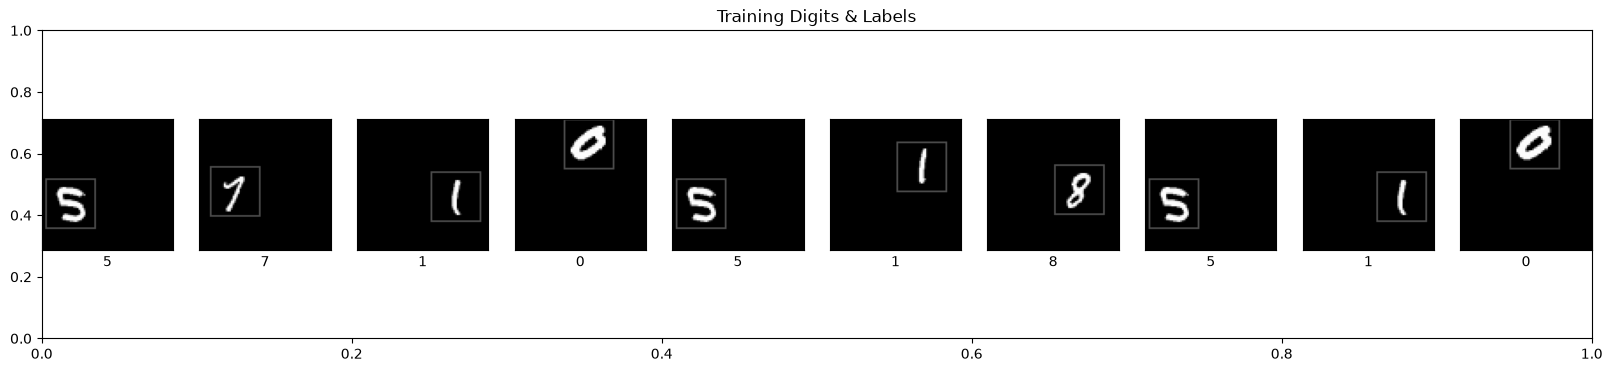

In [17]:
display_digits_with_boxes(
    training_digits,
    training_labels,
    training_labels,
    np.array([]),
    training_bboxes,
    np.array([]),
    "Training Digits & Labels"
)

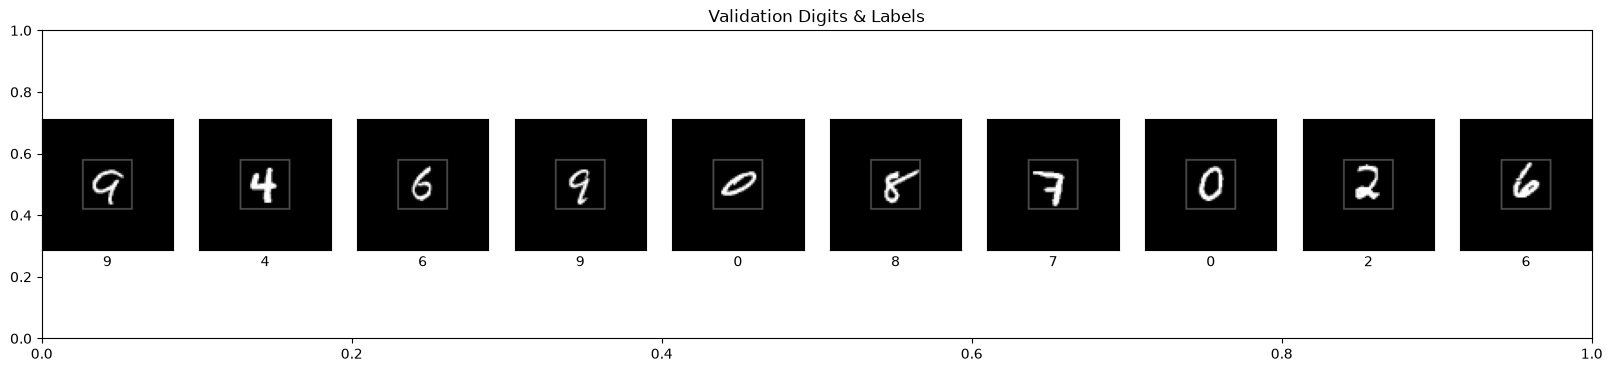

In [18]:
display_digits_with_boxes(validation_digits, validation_labels, validation_labels, np.array([]), validation_bboxes, np.array([]), "Validation Digits & Labels")

In [19]:
#Define the network

In [20]:
def feature_extractor(inputs):
    x = tf.keras.layers.Conv2D(16, activation='relu', kernel_size=3, input_shape=(75,75,1))(inputs)
    x = tf.keras.layers.AveragePooling2D((2,2))(x)

    x = tf.keras.layers.Conv2D(32, activation='relu', kernel_size=3)(x)
    x = tf.keras.layers.AveragePooling2D((2,2))(x)

    x = tf.keras.layers.Conv2D(64, activation='relu', kernel_size=3)(x)
    x = tf.keras.layers.AveragePooling2D((2,2))(x)

    return x

In [21]:
def dense_layers(inputs):
    x = tf.keras.layers.Flatten()(inputs)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    return x
    

In [22]:
def classifier(inputs):
    classification_output = tf.keras.layers.Dense(10, activation="softmax", name="classification")(inputs)
    return classification_output

In [23]:
def bounding_box_regression(inputs):
    bounding_box_regression_output = tf.keras.layers.Dense(
        4,
        activation="sigmoid",
        name="bounding_box"
    )(inputs)

    return bounding_box_regression_output

In [24]:
def final_model(inputs):
    feature_cnn = feature_extractor(inputs)
    dense_output = dense_layers(feature_cnn)

    classification_output = classifier(dense_output)
    bounding_box_output = bounding_box_regression(dense_output)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=[classification_output, bounding_box_output]
    )

    return model

In [25]:
def define_and_compile_model(inputs):
    model = final_model(inputs)

    model.compile(optimizer = 'adam', loss = {'classification' : 'categorical_crossentropy', 'bounding_box' : 'mse'}, metrics = {'classification' : 'accuracy', 'bounding_box' : 'mse'})
    return model

In [26]:
with strategy.scope():
    inputs = tf.keras.layers.Input(shape=(75,75,1))
    model = define_and_compile_model(inputs)

model.summary()

C:\Users\Apurva\anaconda3\envs\petfaces\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 75, 75, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 73, 73, 16)        │             160 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ average_pooling2d             │ (None, 36, 36, 16)        │               0 │ conv2d[0][0]               │
│ (AveragePooling2D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 34, 34, 32)        │           4,640 │ average_pooling2d[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ average_pooling2d_1           │ (None, 17, 17, 32)        │               0 │ conv2d_1[0][0]             │
│ (AveragePooling2D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 15, 15, 64)        │          18,496 │ average_pooling2d_1[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ average_pooling2d_2           │ (None, 7, 7, 64)          │               0 │ conv2d_2[0][0]             │
│ (AveragePooling2D)            │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 3136)              │               0 │ average_pooling2d_2[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │         401,536 │ flatten[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ classification (Dense)        │ (None, 10)                │           1,290 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bounding_box (Dense)          │ (None, 4)                 │             516 │ dense[0][0]                │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 426,638 (1.63 MB)

 Trainable params: 426,638 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
#Train and Validate the model

In [28]:
EPOCHS = 20

steps_per_epoch = 60000 // BATCH_SIZE
validation_steps = 1

history = model.fit(
    training_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_dataset,
    validation_steps=validation_steps,
    epochs=EPOCHS
)

results = model.evaluate( validation_dataset, steps=1, return_dict=True, verbose=1 )
print("\n========== Model Evaluation ==========") 

for metric, value in results.items(): 
    print(f"{metric}: {value:.4f}") 
print("======================================")

Epoch 1/20


C:\Users\Apurva\anaconda3\envs\petfaces\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


937/937 ━━━━━━━━━━━━━━━━━━━━ 109s 111ms/step - bounding_box_loss: 0.0060 - bounding_box_mse: 0.0060 - classification_accuracy: 0.7027 - classification_loss: 0.8656 - loss: 0.8716 - val_bounding_box_loss: 0.0021 - val_bounding_box_mse: 0.0021 - val_classification_accuracy: 0.8576 - val_classification_loss: 0.4567 - val_loss: 0.4588
Epoch 2/20
937/937 ━━━━━━━━━━━━━━━━━━━━ 141s 150ms/step - bounding_box_loss: 0.0022 - bounding_box_mse: 0.0022 - classification_accuracy: 0.9224 - classification_loss: 0.2564 - loss: 0.2586 - val_bounding_box_loss: 0.0014 - val_bounding_box_mse: 0.0014 - val_classification_accuracy: 0.9526 - val_classification_loss: 0.1583 - val_loss: 0.1597
Epoch 3/20
937/937 ━━━━━━━━━━━━━━━━━━━━ 72s 77ms/step - bounding_box_loss: 0.0017 - bounding_box_mse: 0.0017 - classification_accuracy: 0.9427 - classification_loss: 0.1917 - loss: 0.1934 - val_bounding_box_loss: 0.0013 - val_bounding_box_mse: 0.0013 - val_classification_accuracy: 0.9550 - val_classification_loss: 0.1499 

In [29]:
def intersection_over_union(pred_box, true_box):
    pred_box = np.clip(np.array(pred_box), 0, 1)
    true_box = np.clip(np.array(true_box), 0, 1)

    # Ensure correct coordinate ordering: [xmin, ymin, xmax, ymax]
    pred_xmin = min(pred_box[0], pred_box[2])
    pred_ymin = min(pred_box[1], pred_box[3])
    pred_xmax = max(pred_box[0], pred_box[2])
    pred_ymax = max(pred_box[1], pred_box[3])

    true_xmin = min(true_box[0], true_box[2])
    true_ymin = min(true_box[1], true_box[3])
    true_xmax = max(true_box[0], true_box[2])
    true_ymax = max(true_box[1], true_box[3])

    # Intersection area
    x1 = max(pred_xmin, true_xmin)
    y1 = max(pred_ymin, true_ymin)
    x2 = min(pred_xmax, true_xmax)
    y2 = min(pred_ymax, true_ymax)

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    # Individual box areas
    pred_area = (pred_xmax - pred_xmin) * (pred_ymax - pred_ymin)
    true_area = (true_xmax - true_xmin) * (true_ymax - true_ymin)

    union = pred_area + true_area - intersection

    return intersection / union if union > 0 else 0.0

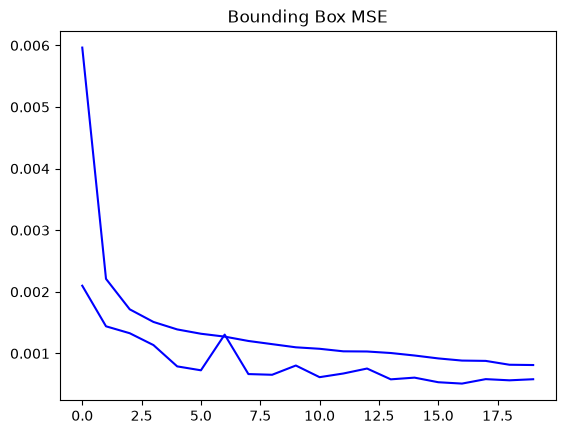

In [30]:
plot_metrics("bounding_box_mse", "Bounding Box MSE")

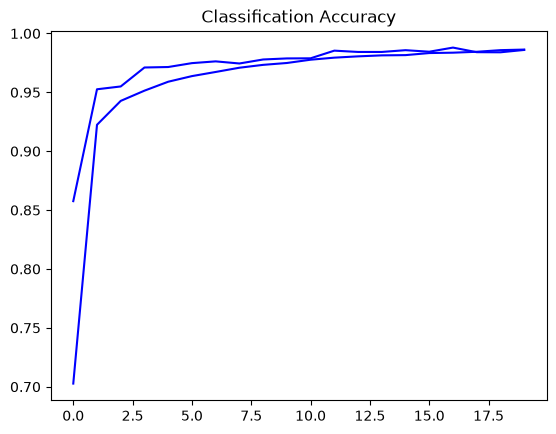

In [31]:
plot_metrics("classification_accuracy", "Classification Accuracy")

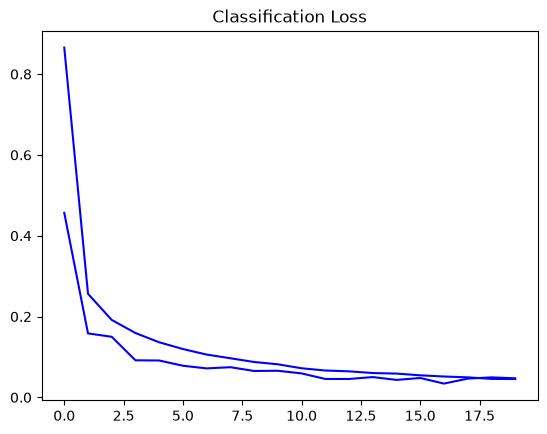

In [32]:
plot_metrics("classification_loss", "Classification Loss")

157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step
Mean IoU: 0.8110
Bounding Boxes with IoU >= 0.5: 99.99%


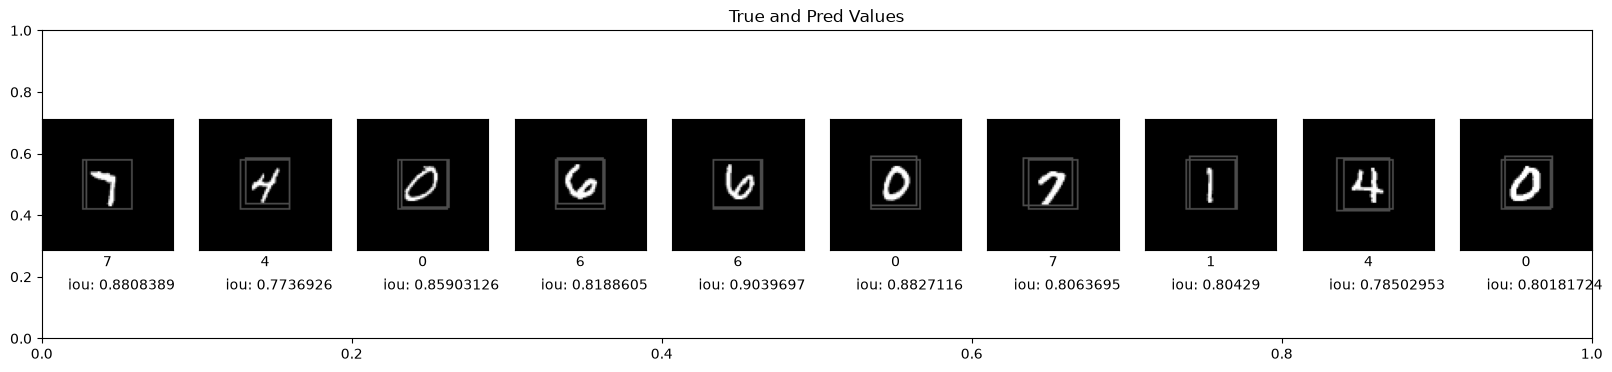

In [33]:
prediction = model.predict(validation_digits, batch_size=64)

predicted_labels = np.argmax(prediction[0], axis=1)
prediction_bboxes = prediction[1]

# Calculate IoU for all validation images
ious = np.array([
    intersection_over_union(pred_box, true_box)
    for pred_box, true_box in zip(prediction_bboxes, validation_bboxes)
]).reshape(-1, 1)

mean_iou = np.mean(ious)
iou_50 = np.mean(ious >= 0.5) * 100

print(f"Mean IoU: {mean_iou:.4f}")
print(f"Bounding Boxes with IoU >= 0.5: {iou_50:.2f}%")

# Use individual IoU values for visualization
iou_threshold = 0.6

display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    ious,
    "True and Pred Values"
)